# 39. Lag relationships and three-day forecast diagnostics

**Purpose:** compare monthly within-ZIP lag relationships, then test four controlled Dynamic Panel FE lag configurations.

May, August and November 2020 describe different calendar periods. These are descriptive comparisons, not causal estimates. The line in each scatterplot uses a common within-ZIP slope and an intercept at the grand mean.

Forecast diagnostics retain today's cases, both commuting-pressure inputs, calendar indicators and ZIP fixed effects. Other derived local-history inputs are excluded so they do not indirectly supply the lags being compared. This is a controlled diagnostic, not a replacement for the full models.

60-day rolling calendar window, 14-day warmup, weekly refits. All training targets have occurred by the fit date. Evaluate the same 585 ZIPs and 243 forecast dates from April 30 to December 28, 2020, at horizons 1–3. Onset-date availability is retrospective and does not establish real-time availability.


In [1]:
from pathlib import Path
import json,numpy as np,pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
ROOT=Path(r'C:/Users/41240/OneDrive/文档/GitHub/practicum-project/Weikun')
def run(root=ROOT,output=Path('outputs/lag_analysis/results')):
 output=Path(output);output.mkdir(parents=True,exist_ok=True);(output/'figures').mkdir(exist_ok=True)
 ids=pd.read_csv(root/'fixed60_trajectory_outputs/fixed60_20261027/common_regions.csv',dtype={'zip':str}).zip.to_numpy();dates=pd.date_range('2020-03-01','2020-12-31')
 cols=['cases_today','cases_lag_1','cases_lag_7','cases_lag_14','nj_covid_pressure_7d','nj_covid_pressure_14d']
 f=pd.read_csv(root/'rolling_trajectory_outputs/inputs/nj_daily_features.csv.gz',usecols=['zip','date']+cols,dtype={'zip':str},parse_dates=['date']);f=f[f.zip.isin(ids)&f.date.isin(dates)]
 assert len(ids)==585 and not f.duplicated(['zip','date']).any()
 ar={c:f.pivot(index='zip',columns='date',values=c).reindex(index=ids,columns=dates).to_numpy(float) for c in cols};y=ar['cases_today'];assert np.isfinite(y).all()
 plt.rcParams.update({'font.family':'Arial','font.size':11,'axes.spines.top':False,'axes.spines.right':False})
 rng=np.random.default_rng(20261104);rows=[];fig,ax=plt.subplots(2,3,figsize=(13,6.5))
 for j,month in enumerate([5,8,11]):
  ix=np.flatnonzero(dates.month==month)
  for i,lag in enumerate([1,7]):
   x=ar[f'cases_lag_{lag}'][:,ix];z=y[:,ix];xc=x-x.mean(1,keepdims=True);zc=z-z.mean(1,keepdims=True);num=(xc*zc).sum(0);den=(xc*xc).sum(0);slope=num.sum()/den.sum()
   B=2000;starts=rng.integers(0,len(ix),size=(B,int(np.ceil(len(ix)/7))));bi=((starts[:,:,None]+np.arange(7))%len(ix)).reshape(B,-1)[:,:len(ix)]
   # Resample whole daily cross-sections and recompute within-ZIP centering.
   bs=[]
   for k in bi:
    xx=x[:,k];zz=z[:,k];xx=xx-xx.mean(1,keepdims=True);zz=zz-zz.mean(1,keepdims=True);dd=(xx*xx).sum();bs.append((xx*zz).sum()/dd if dd else np.nan)
   lo,hi=np.nanquantile(bs,[.025,.975]);a=ax[i,j];a.scatter(x.ravel(),z.ravel(),s=3,alpha=.14,color=['#2563EB','#087F78'][i],rasterized=True);inter=z.mean()-slope*x.mean();line=np.linspace(0,x.max(),100);a.plot(line,inter+slope*line,color='#173654');a.set_title(f'{dates[ix[0]]:%b 2020}: lag {lag}\nWithin-ZIP slope {slope:.2f}');a.set_xlabel(f'Cases {lag} day(s) earlier');a.set_ylabel('Current daily cases');rows.append(dict(month=month,lag=lag,within_zip_slope=slope,ci95_low=lo,ci95_high=hi,observations=x.size))
 fig.tight_layout();fig.savefig(output/'figures/lag_relationships.png',dpi=220);plt.close(fig);pd.DataFrame(rows).to_csv(output/'monthly_lag_relationships.csv',index=False)
 variants={'L1':['cases_lag_1'],'L7':['cases_lag_7'],'L1_L7':['cases_lag_1','cases_lag_7'],'L1_L7_L14':['cases_lag_1','cases_lag_7','cases_lag_14']}
 origins=np.flatnonzero((dates>='2020-04-30')&(dates<='2020-12-28'));truth=np.stack([y[:,origins+h] for h in [1,2,3]],2);pred={v:np.full_like(truth,np.nan) for v in variants};audit=[];coefs=[];first=dates.get_loc('2020-04-29')
 for fit in np.unique(first+7*((origins-first)//7)):
  lo=fit-59;batch=np.flatnonzero((origins>=fit)&(origins<fit+7))
  for hh,h in enumerate([1,2,3]):
   train=np.arange(lo+14,fit-h+1);assert train[-1]+h<=fit and np.all(origins[batch]>fit-1)
   target=dates+pd.Timedelta(days=h)
   for k in range(2,8):ar[f'weekday_{k}']=np.broadcast_to((target.dayofweek==k-1).astype(float),y.shape)
   for k in range(2,13):ar[f'month_{k}']=np.broadcast_to((target.month==k).astype(float),y.shape)
   yt=y[:,train+h];ym=yt.mean(1);yc=yt-ym[:,None]
   for name,lags in variants.items():
    features=['cases_today']+lags+cols[-2:]+[f'weekday_{k}' for k in range(2,8)]+[f'month_{k}' for k in range(2,13)]
    xx=np.stack([ar[c][:,train] for c in features],2);pp=np.stack([ar[c][:,origins[batch]] for c in features],2);assert np.isfinite(xx).all() and np.isfinite(pp).all();xm=xx.mean(1);xc=xx-xm[:,None];norm=np.sqrt((xc*xc).mean((0,1)));scale=np.where(norm>1e-10,norm,1);zz=(xc/scale).reshape(-1,len(features));keep=[];q=[]
    for k in range(len(features)):
     if norm[k]<1e-10:continue
     v=zz[:,k].copy()
     for _ in range(2):
      for u in q:v-=u*(u@v)
     length=np.linalg.norm(v)
     if length<=1e-7*np.sqrt(len(v)):continue
     keep.append(k);q.append(v/length)
    b=np.linalg.lstsq(zz[:,keep],yc.ravel(),rcond=None)[0]/scale[keep];ph=np.einsum('ntp,p->nt',pp[:,:,keep],b)+(ym-xm[:,keep]@b)[:,None];pred[name][:,batch,hh]=np.maximum(ph,0)
    for k,coef in zip(keep,b):coefs.append(dict(variant=name,fit_date=str(dates[fit].date()),horizon=h,feature=features[k],coefficient=coef))
    audit.append(dict(variant=name,horizon=h,window_start=str(dates[lo].date()),fit_date=str(dates[fit].date()),latest_training_target=str(dates[train[-1]+h].date()),first_forecast_date=str(dates[origins[batch[0]]].date()),features=json.dumps(features)))
  print('Completed',dates[fit].date(),flush=True)
 metrics=[];daily={}
 for name,p in pred.items():
  assert np.isfinite(p).all();e=p-truth;daily[name]=np.abs(e).mean((0,2));direction=(np.sign(p[:,:,2]-p[:,:,0])==np.sign(truth[:,:,2]-truth[:,:,0])).mean();metrics.append(dict(variant=name,MAE=np.abs(e).mean(),RMSE=np.sqrt((e*e).mean()),bias=e.mean(),direction_accuracy=direction))
  np.savez_compressed(output/f'predictions_{name}.npz',predictions=p,actual_cases=truth,zip=ids,daily_forecast_dates=dates[origins].to_numpy())
 pd.DataFrame(metrics).to_csv(output/'validation_metrics.csv',index=False);pd.DataFrame(audit).to_csv(output/'training_audit.csv',index=False);pd.DataFrame(coefs).to_csv(output/'coefficients_by_fit.csv',index=False)
 tests=[]
 for name in list(variants)[1:]:
  delta=daily['L1']-daily[name];r=sm.OLS(delta,np.ones((len(delta),1))).fit(cov_type='HAC',cov_kwds={'maxlags':7});r28=sm.OLS(delta,np.ones((len(delta),1))).fit(cov_type='HAC',cov_kwds={'maxlags':28});starts=rng.integers(0,len(delta),size=(4000,int(np.ceil(len(delta)/14))));bi=((starts[:,:,None]+np.arange(14))%len(delta)).reshape(4000,-1)[:,:len(delta)];ci=np.quantile(delta[bi].mean(1),[.025,.975]);tests.append(dict(candidate=name,delta_MAE_L1_minus_candidate=delta.mean(),ci95_low=ci[0],ci95_high=ci[1],p_HAC7=r.pvalues[0],p_HAC28=r28.pvalues[0]))
 t=pd.DataFrame(tests);t['p_Holm_HAC7']=multipletests(t.p_HAC7,method='holm')[1];t['p_Holm_HAC28']=multipletests(t.p_HAC28,method='holm')[1];t.to_csv(output/'paired_comparisons.csv',index=False)
 m=pd.DataFrame(metrics);fig,axs=plt.subplots(1,3,figsize=(13,4))
 for a,col,title in zip(axs,['MAE','RMSE','direction_accuracy'],['Three-day path MAE','Three-day path RMSE','Endpoint direction accuracy']):
  v=m[col].to_numpy();v=v*100 if col=='direction_accuracy' else v;b=a.bar(m.variant,v,color=['#64748B','#88AEC1','#2563EB','#087F78']);a.bar_label(b,labels=[f'{x:.1f}%' if col=='direction_accuracy' else f'{x:.3f}' for x in v],padding=4);a.set_ylim(0,max(v)*1.22);a.set_title(title);a.grid(axis='y',alpha=.2);a.set_axisbelow(True)
 fig.tight_layout();fig.savefig(output/'figures/lag_prediction_comparison.png',dpi=220);plt.close(fig)
 protocol={'scope':'2020 exploratory development only','regions':585,'dates':243,'window':60,'refit':7,'warmup':14,'common_inputs':'cases_today, pressure7/14, target weekday/month, ZIP FE','excluded':'rolling means/std, local population rates, acceleration/jerk, sparse history, to avoid indirect lag information','variants':variants,'descriptive':'within-ZIP monthly slope with7day circular date-block bootstrap2000 pointwise CI. Whole ZIP cross sections resampled, few monthly blocks limits inference. Association not causation or GMM.','forecast_tests':'paired daily losses;HAC7/HAC28;Holm3contrasts separately;14day dateblockbootstrap4000 pointwiseCI','availability':'retrospective onset counts;real-time reporting availability unverified','main_models':'unchanged;diagnostic FE configurations only'}
 (output/'protocol.json').write_text(json.dumps(protocol,indent=2),encoding='utf-8');(output/'RESULTS.md').write_text('# Lag analysis\n\n'+pd.DataFrame(rows).to_markdown(index=False)+'\n\n'+m.to_markdown(index=False)+'\n\n'+t.to_markdown(index=False)+'\n\nPositive paired delta means candidate improves MAE over L1. Descriptive slopes and prediction gains answer different questions. No GMM validity tests or causal claims. Main models unchanged.\n',encoding='utf-8');return m


In [2]:
ROOT=Path.cwd()
if not (ROOT/'rolling_trajectory_outputs').exists() and (ROOT/'Weikun').is_dir(): ROOT=ROOT/'Weikun'
OUTPUT=ROOT/'mentor_followup_outputs'/'2026-11-04'/'lag_analysis'
metrics=run(ROOT,OUTPUT)
display(metrics)

Completed 2020-04-29
Completed 2020-05-06
Completed 2020-05-13
Completed 2020-05-20
Completed 2020-05-27
Completed 2020-06-03
Completed 2020-06-10
Completed 2020-06-17
Completed 2020-06-24
Completed 2020-07-01
Completed 2020-07-08
Completed 2020-07-15
Completed 2020-07-22
Completed 2020-07-29
Completed 2020-08-05
Completed 2020-08-12
Completed 2020-08-19
Completed 2020-08-26
Completed 2020-09-02
Completed 2020-09-09
Completed 2020-09-16
Completed 2020-09-23
Completed 2020-09-30
Completed 2020-10-07
Completed 2020-10-14
Completed 2020-10-21
Completed 2020-10-28
Completed 2020-11-04
Completed 2020-11-11
Completed 2020-11-18
Completed 2020-11-25
Completed 2020-12-02
Completed 2020-12-09
Completed 2020-12-16
Completed 2020-12-23


,variant,MAE,RMSE,bias,direction_accuracy
0,L1,0.796049,1.465739,0.081549,0.345996
1,L7,0.818487,1.518239,0.093389,0.348197
2,L1_L7,0.788096,1.455250,0.074987,0.340586
3,L1_L7_L14,0.791637,1.464964,0.078063,0.338462


,month,lag,within_zip_slope,ci95_low,ci95_high,observations
0,5,1,0.198089,-0.020698,0.288849,18135
1,5,7,0.207786,0.057192,0.316171,18135
2,8,1,0.087828,-0.024504,0.095107,18135
3,8,7,-0.009029,-0.043360,0.030888,18135
4,11,1,0.128432,-0.019841,0.196659,17550
5,11,7,0.144960,0.042279,0.262517,17550


,candidate,delta_MAE_L1_minus_candidate,ci95_low,ci95_high,p_HAC7,p_HAC28,p_Holm_HAC7,p_Holm_HAC28
0,L7,-0.022438,-0.033142,-0.012561,2.919548e-07,0.001094,8.758645e-07,0.003281
1,L1_L7,0.007952,0.003309,0.013758,2.115080e-04,0.022960,4.230159e-04,0.045920
2,L1_L7_L14,0.004412,-0.004313,0.013514,2.257799e-01,0.409075,2.257799e-01,0.409075


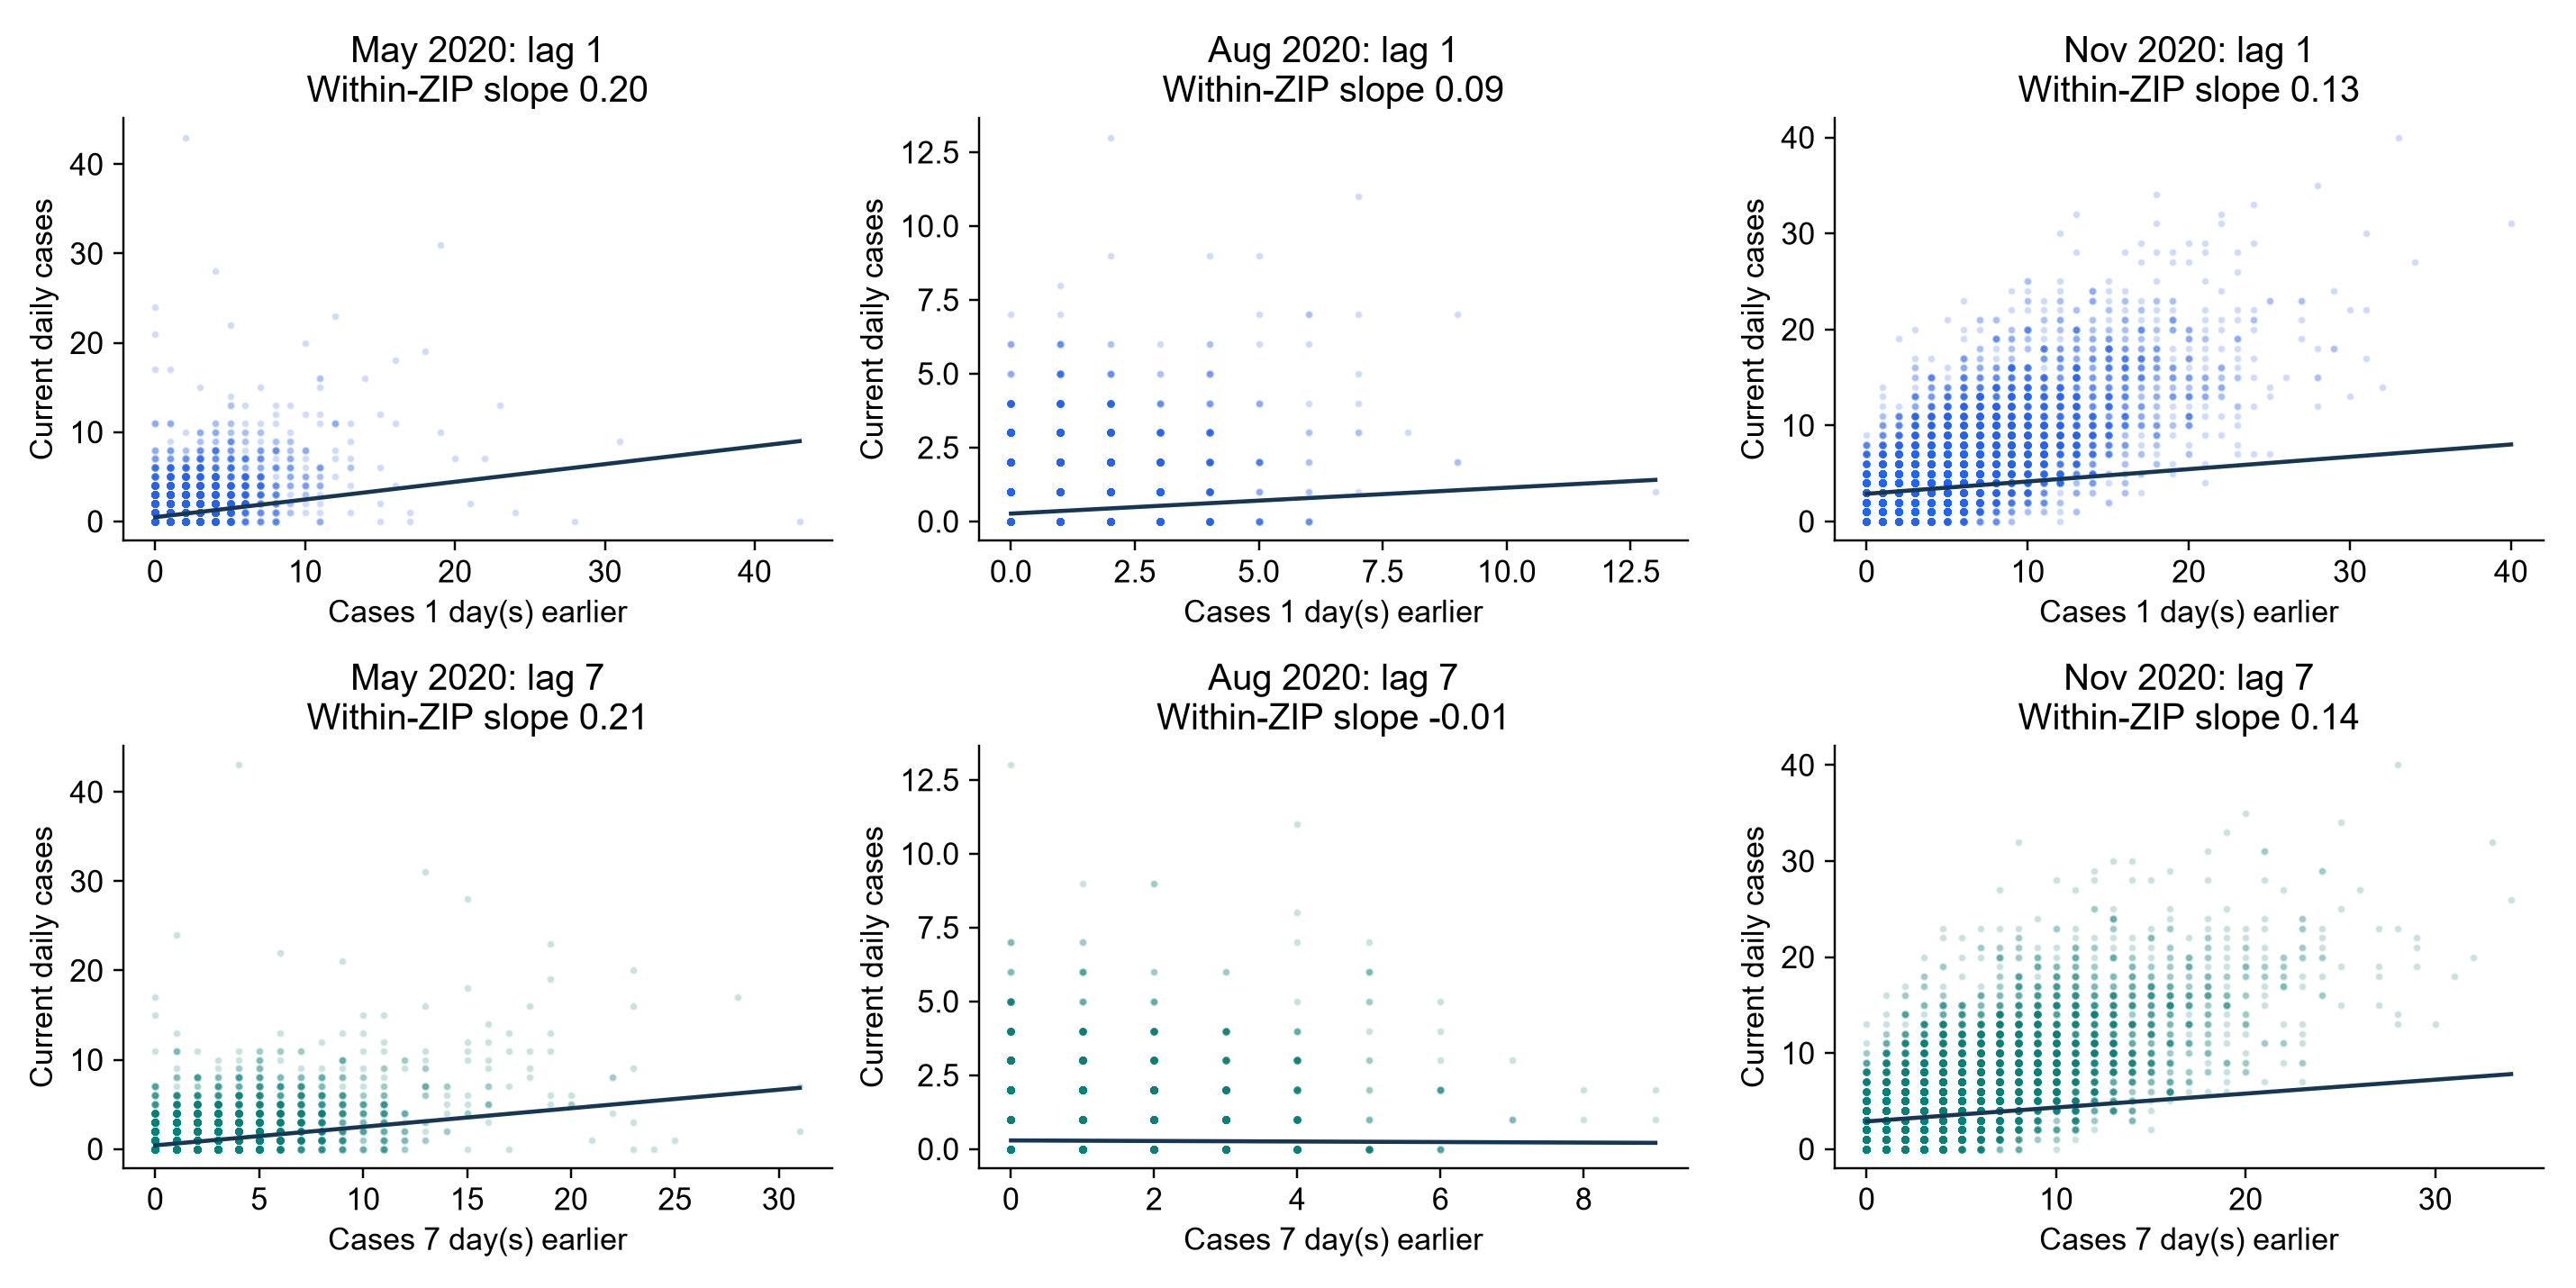

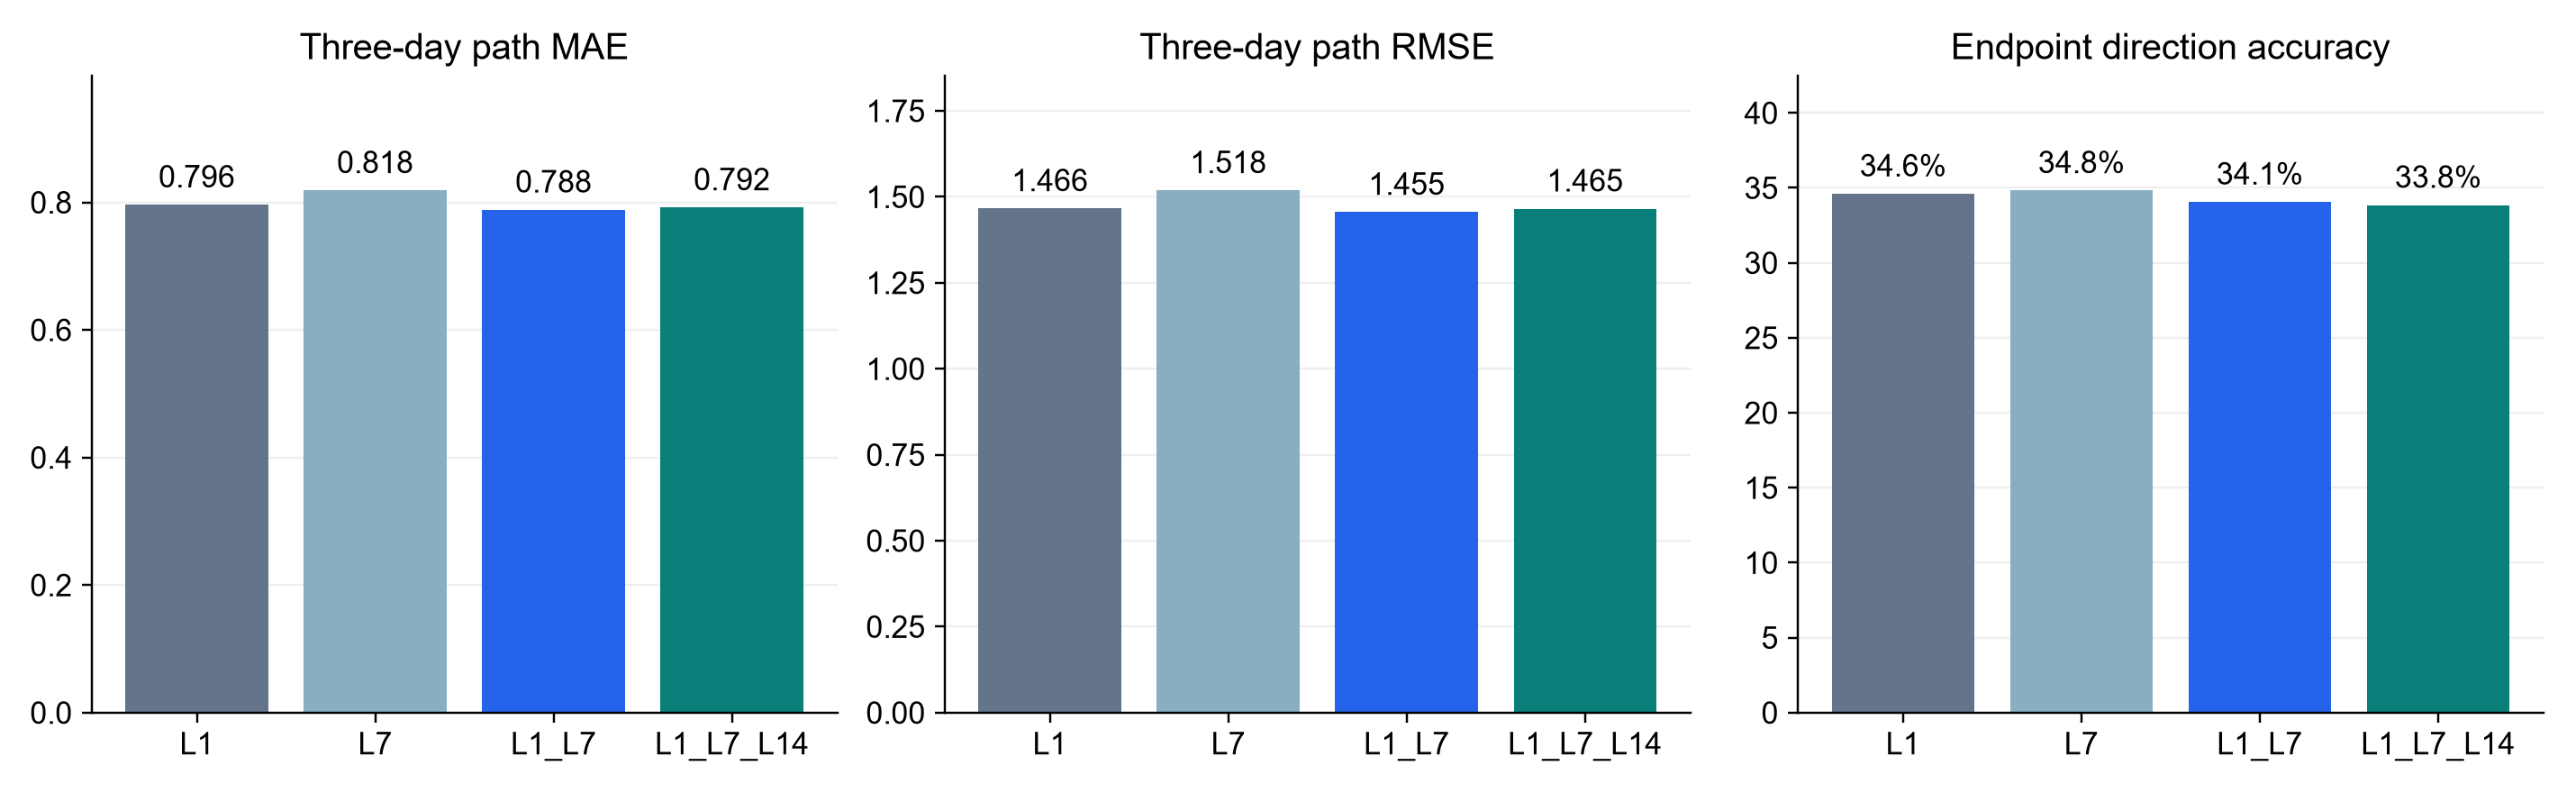

In [3]:
from IPython.display import Image,display
display(pd.read_csv(OUTPUT/'monthly_lag_relationships.csv'))
display(pd.read_csv(OUTPUT/'paired_comparisons.csv'))
display(Image(filename=str(OUTPUT/'figures/lag_relationships.png')))
display(Image(filename=str(OUTPUT/'figures/lag_prediction_comparison.png')))

## Interpretation
Positive paired delta means the candidate reduces MAE compared with L1. Report pointwise bootstrap intervals alongside Holm-adjusted HAC7 and HAC28 sensitivity p-values. Coefficients from overlapping refits describe stability, not independent evidence. Monthly relationship strength does not establish out-of-sample prediction gains. Lag 7 is an input from seven days ago and does not imply seven days of warning lead time.

Do not report Sargan or Arellano–Bond tests: these fits use FE least squares, not GMM. No untouched test claim or automatic feature selection. Main full-feature models remain unchanged.
